# Lab 7: Explainable AI, Adversarial AI and Advanced Applications
## Experiment 3: Dimensionality Reduction using PCA and SVD

This notebook implements and contrasts **Principal Component Analysis (PCA)** and **Singular Value Decomposition (SVD)** on the canonical Iris dataset.

### Key Objectives:
1. Load, inspect, and standardize the 4-dimensional **Iris dataset** using Scikit-Learn.
2. Formulate the mathematical principles of dimensionality reduction and variance maximization.
3. Compute Principal Component Analysis (PCA), extracting explained variance ratios across all orthogonal axes.
4. Project samples onto a 2-dimensional subspace and visualize class separation.
5. Decompose the standardized data matrix via Singular Value Decomposition (SVD): $X = U \Sigma V^T$.
6. Prove the mathematical equivalence between PCA projections and SVD singular coordinates.
7. Quantify and discuss the trade-offs of information loss in reduced feature spaces.


---
### 1. Import Required Libraries and Configure Environment
We import NumPy, Pandas, Matplotlib, Seaborn, and Scikit-Learn modules.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

OUTPUT_DIR = Path("Lab7/outputs") if Path("Lab7").exists() else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output Directory: {OUTPUT_DIR.resolve()}")


Output Directory: /home/jeet/Desktop/Artificial_Intelligence/Lab7/outputs


---
### 2. Loading and Inspecting the Iris Dataset
The Iris dataset contains 150 botanical observations measured across 4 physical dimensions: Sepal Length, Sepal Width, Petal Length, and Petal Width, distributed across 3 iris species: *Setosa*, *Versicolour*, and *Virginica*.


In [2]:
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

df = pd.DataFrame(X, columns=feature_names)
df["species"] = [target_names[i] for i in y]

print(f"Dataset Shape  : {X.shape} (150 samples, 4 features)")
print(f"Feature Names  : {feature_names}")
print(f"Class Labels   : {list(target_names)}")
display(df.head())


Dataset Shape  : (150, 4) (150 samples, 4 features)
Feature Names  : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class Labels   : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


---
### 3. Feature Standardization
Dimensionality reduction algorithms maximize variance along orthogonal projection axes. Features measured on larger numerical scales would artificially dominate the principal directions. We apply `StandardScaler` to ensure zero mean ($\mu = 0$) and unit variance ($\sigma = 1$) across all dimensions.


In [3]:
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

std_check = pd.DataFrame({
    "Mean": X_std.mean(axis=0).round(4),
    "Std Dev": X_std.std(axis=0).round(4)
}, index=feature_names)
print("Standardized Feature Verification:")
display(std_check)


Standardized Feature Verification:


,Mean,Std Dev
sepal length (cm),-0.0,1.0
sepal width (cm),-0.0,1.0
petal length (cm),-0.0,1.0
petal width (cm),-0.0,1.0


---
### 4. Principal Component Analysis (PCA) Mathematical Formulation
**Principal Component Analysis (PCA)** finds an orthogonal linear transformation $V$ that maps data $X$ to a new coordinate system such that:
1. The first principal component (PC1) accounts for the largest possible variance.
2. Each succeeding component is orthogonal to the preceding components and accounts for the maximum remaining variance.

Mathematically, this corresponds to the spectral eigen-decomposition of the sample covariance matrix $\Sigma$:
$$\Sigma = \frac{1}{N-1} X^T X = V \Lambda V^T$$
where $V$ contains the orthogonal eigenvectors (principal component directions) and $\Lambda$ contains the descending eigenvalues $\lambda_i$.


---
### 5. Fitting PCA and Analyzing Explained Variance
We fit PCA with all 4 components to evaluate the eigenvalue distribution and cumulative variance ratio.


In [4]:
pca_full = PCA(n_components=4)
pca_full.fit(X_std)

var_ratios = pca_full.explained_variance_ratio_
cum_var = np.cumsum(var_ratios)

variance_table = pd.DataFrame({
    "Principal Component": [f"PC{i+1}" for i in range(4)],
    "Eigenvalue (Variance)": pca_full.explained_variance_.round(4),
    "Explained Variance Ratio": var_ratios.round(4),
    "Explained Variance (%)": (var_ratios * 100).round(2),
    "Cumulative Variance (%)": (cum_var * 100).round(2)
})
display(variance_table)


,Principal Component,Eigenvalue (Variance),Explained Variance Ratio,Explained Variance (%),Cumulative Variance (%)
0,PC1,2.9381,0.7296,72.96,72.96
1,PC2,0.9202,0.2285,22.85,95.81
2,PC3,0.1477,0.0367,3.67,99.48
3,PC4,0.0209,0.0052,0.52,100.00


---
### 6. Scree Plot and Cumulative Variance Visualization
We construct a Scree Plot to visualize the drop in explanatory power across principal components.


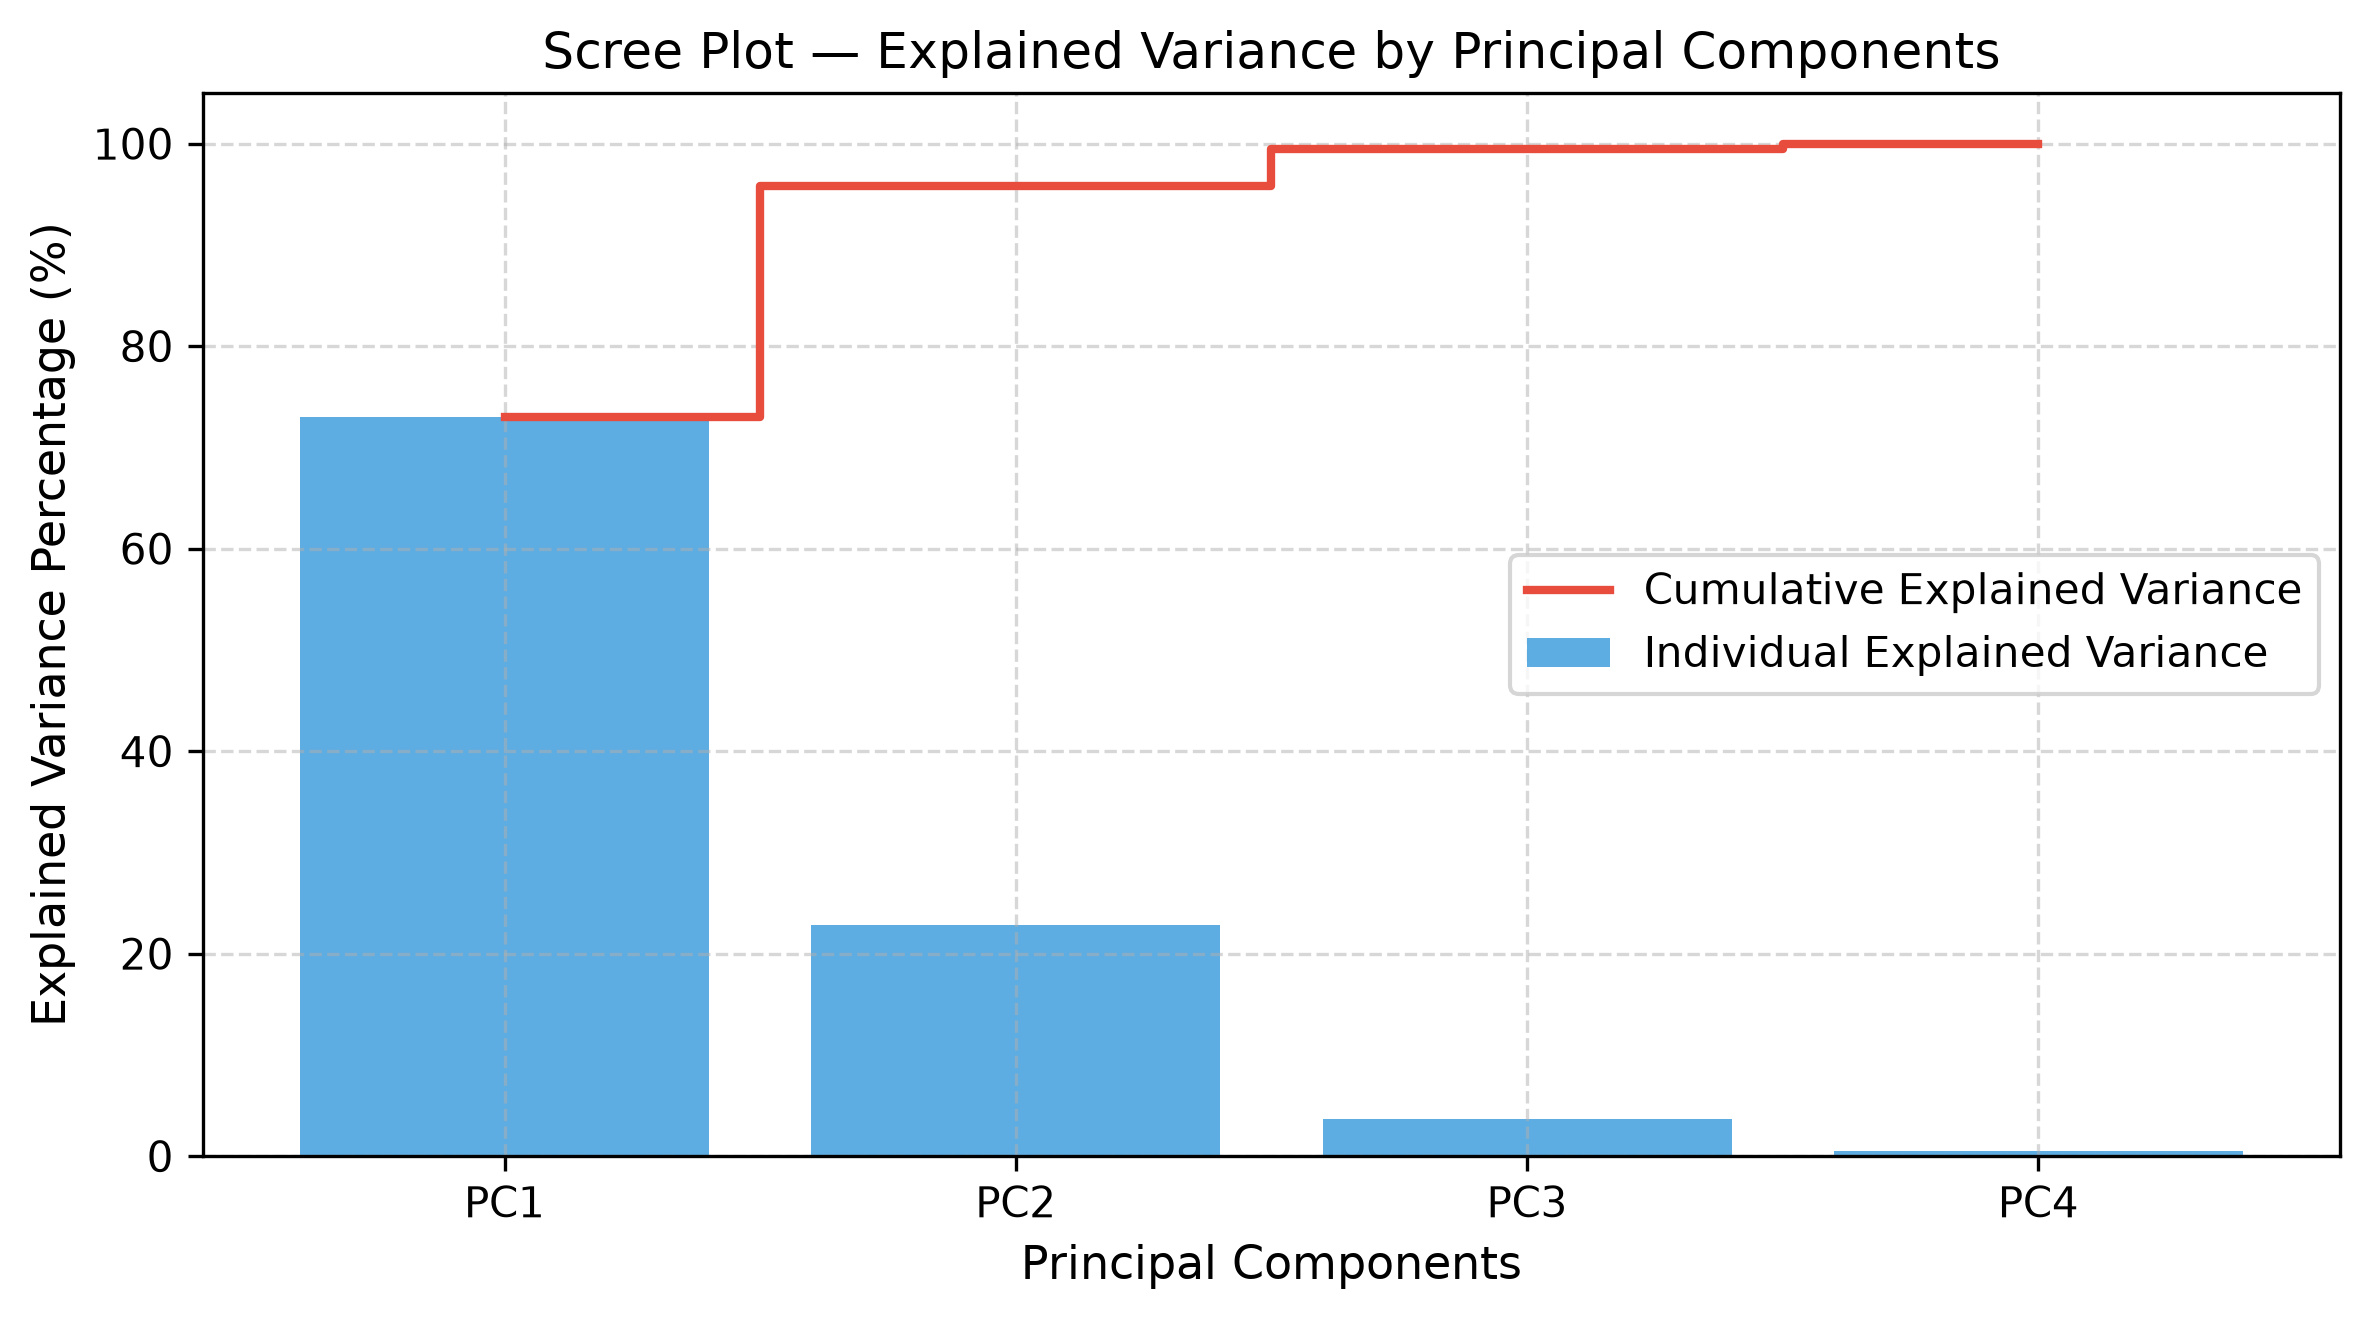

In [5]:
plt.figure(figsize=(8, 4.5), dpi=300)
x_bars = [f"PC{i+1}" for i in range(4)]
plt.bar(x_bars, var_ratios * 100, color="#3498db", alpha=0.8, label="Individual Explained Variance")
plt.step(x_bars, cum_var * 100, where="mid", color="#e74c3c", lw=2, label="Cumulative Explained Variance")
plt.title("Scree Plot — Explained Variance by Principal Components", fontsize=12)
plt.xlabel("Principal Components", fontsize=11)
plt.ylabel("Explained Variance Percentage (%)", fontsize=11)
plt.ylim(0, 105)
plt.legend(loc="center right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


---
### 7. Transforming to 2D Subspace and Visualizing Class Separation
Because PC1 ($72.96\%$) and PC2 ($22.85\%$) jointly capture **$95.81\%$** of total dataset variance, reducing the dataset from 4 dimensions to 2 dimensions preserves nearly all meaningful statistical information.


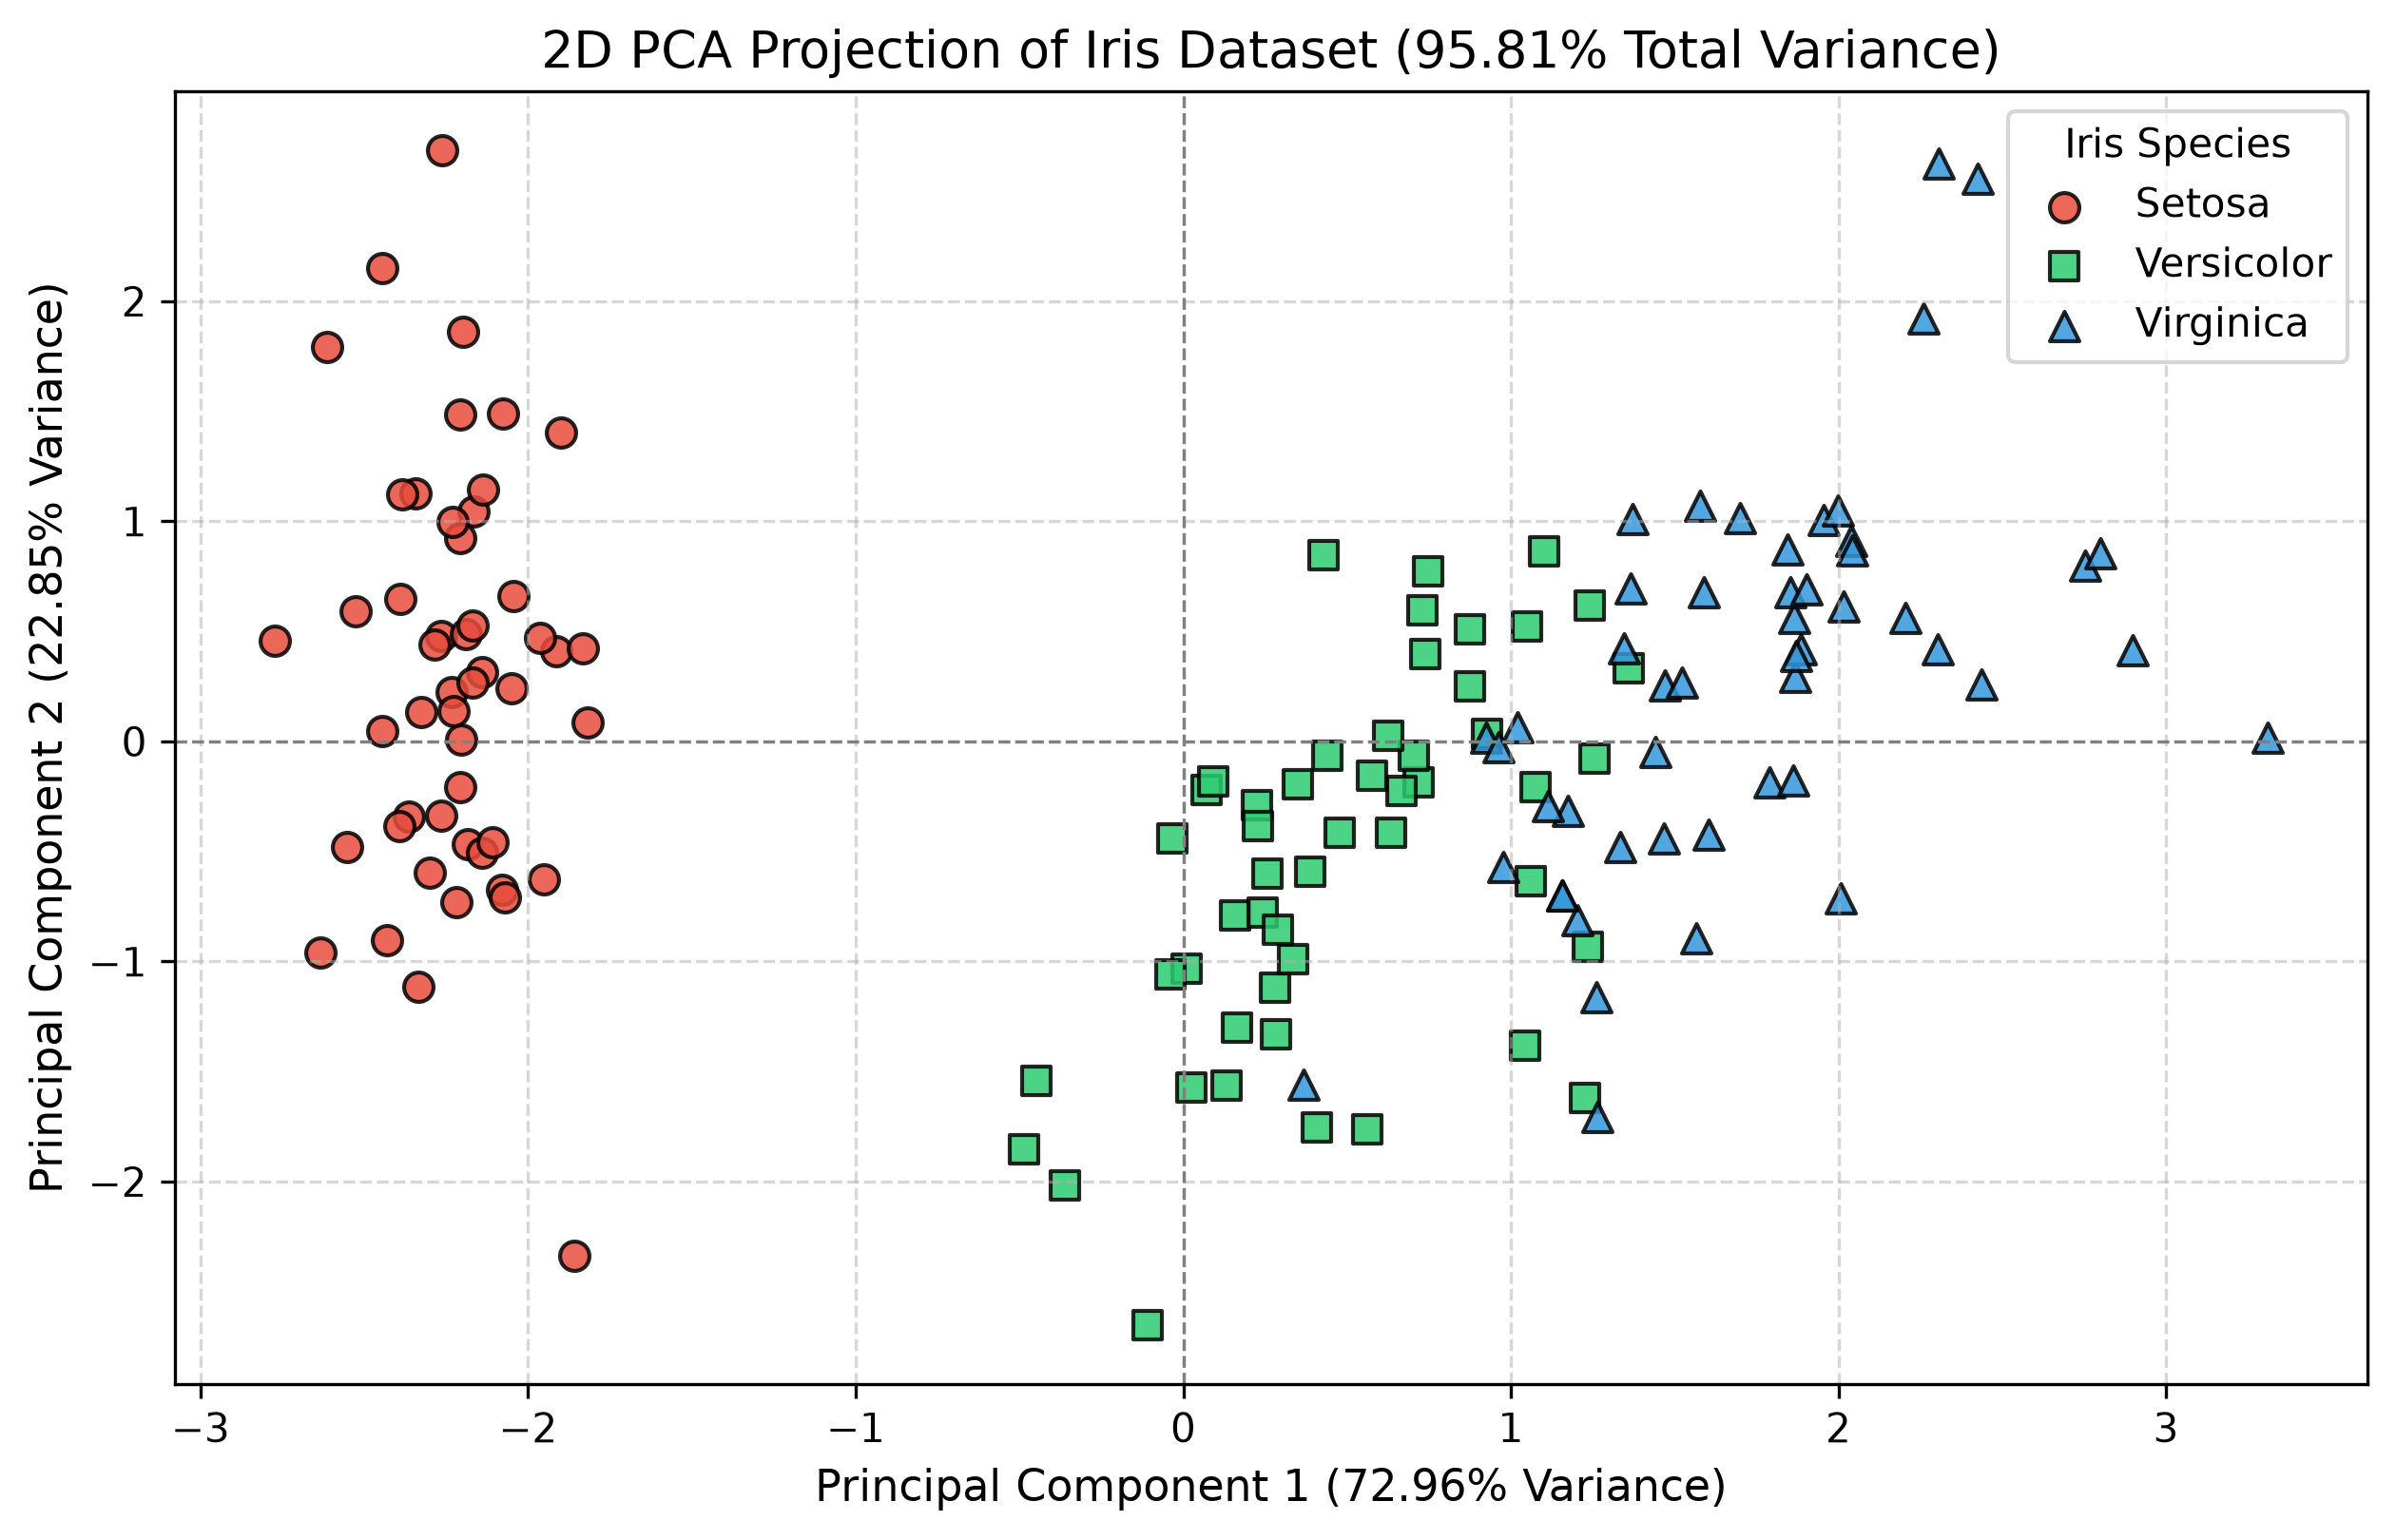

PCA visualization plot saved to: outputs/pca_visualization.png


In [6]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_std)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Species": [target_names[i] for i in y]
})

plt.figure(figsize=(8.5, 5.5), dpi=300)
colors = {"setosa": "#e74c3c", "versicolor": "#2ecc71", "virginica": "#3498db"}
markers = {"setosa": "o", "versicolor": "s", "virginica": "^"}

for sp in target_names:
    subset = pca_df[pca_df["Species"] == sp]
    plt.scatter(subset["PC1"], subset["PC2"], label=sp.capitalize(), color=colors[sp], marker=markers[sp], s=55, alpha=0.85, edgecolors="k")

plt.title("2D PCA Projection of Iris Dataset (95.81% Total Variance)", fontsize=13)
plt.xlabel(f"Principal Component 1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}% Variance)", fontsize=11)
plt.ylabel(f"Principal Component 2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}% Variance)", fontsize=11)
plt.axhline(0, color="gray", linestyle="--", lw=0.8)
plt.axvline(0, color="gray", linestyle="--", lw=0.8)
plt.legend(title="Iris Species", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

pca_out_path = OUTPUT_DIR / "pca_visualization.png"
plt.savefig(pca_out_path)
plt.show()
print(f"PCA visualization plot saved to: {pca_out_path}")


---
### 8. Interpreting Principal Component Loadings
The eigenvectors (loadings) indicate the mathematical correlation between original features and the synthesized principal axes.


Principal Component Loadings (Eigenvectors):


,PC1,PC2
sepal length (cm),0.521066,0.377418
sepal width (cm),-0.269347,0.923296
petal length (cm),0.580413,0.024492
petal width (cm),0.564857,0.066942


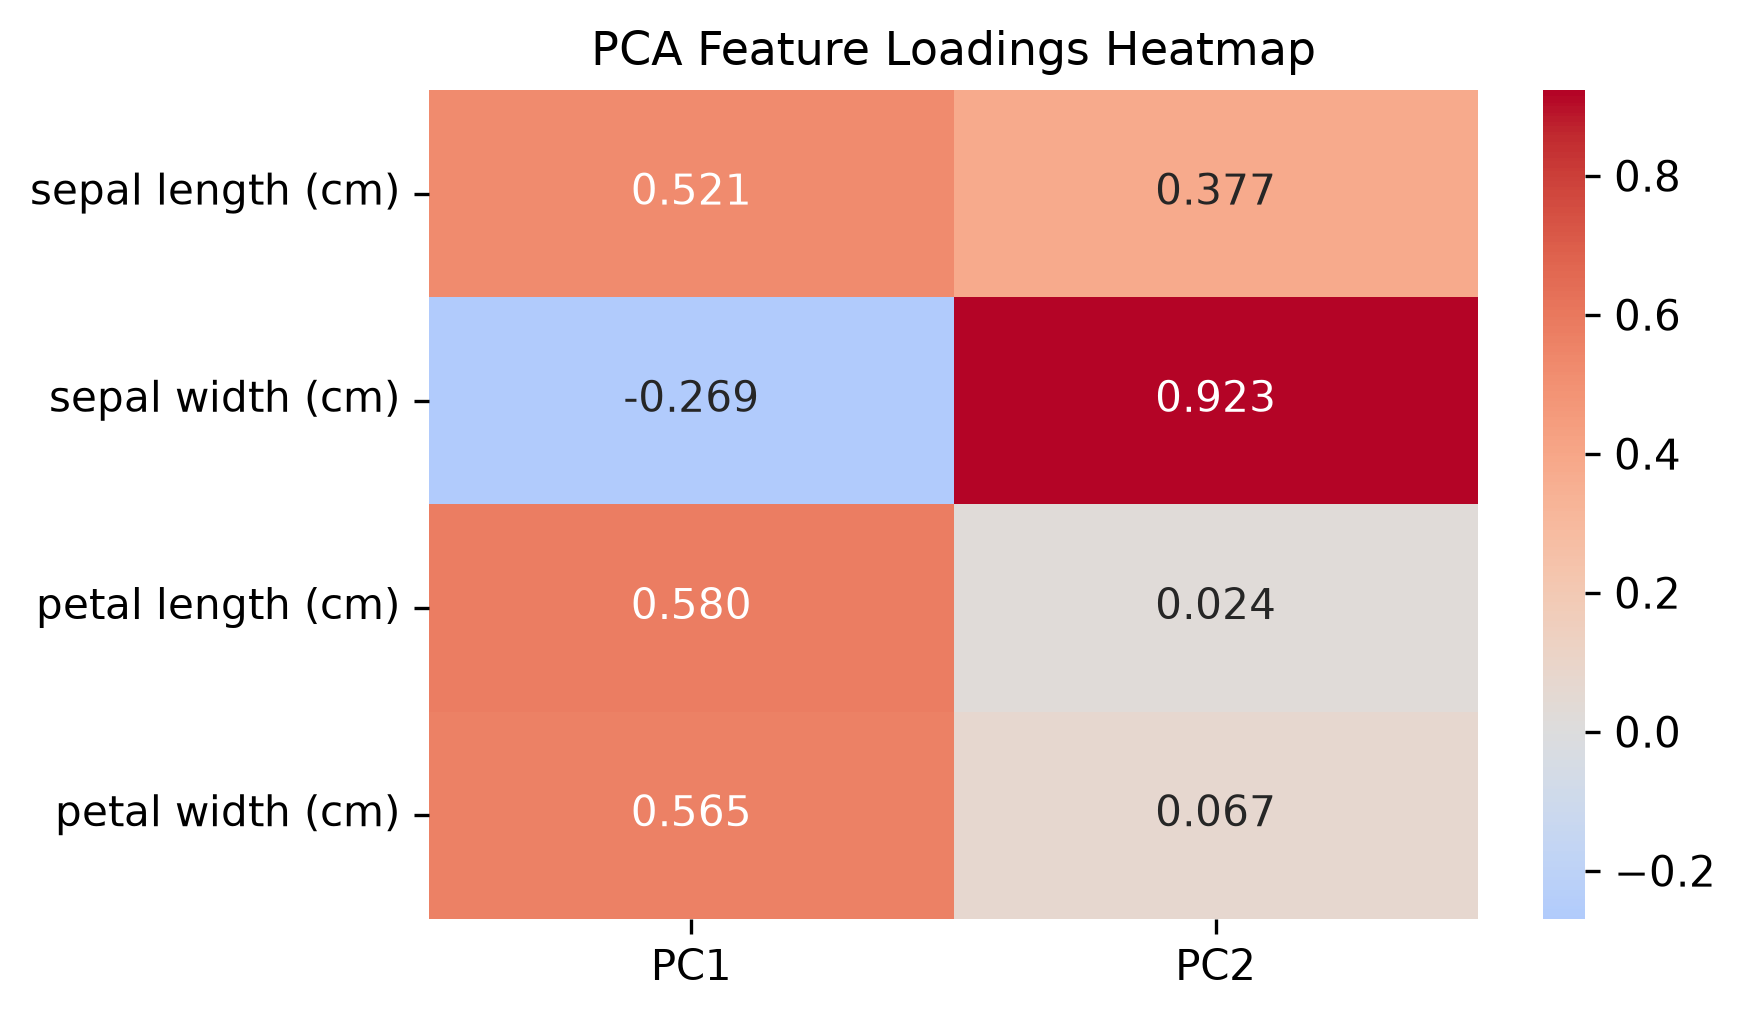

In [7]:
loadings = pd.DataFrame(
    pca_2d.components_.T,
    columns=["PC1", "PC2"],
    index=feature_names
)
print("Principal Component Loadings (Eigenvectors):")
display(loadings)

plt.figure(figsize=(6, 3.5), dpi=300)
sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0, fmt=".3f")
plt.title("PCA Feature Loadings Heatmap", fontsize=11)
plt.tight_layout()
plt.show()


---
### 9. Singular Value Decomposition (SVD) Mathematical Formulation
Any real matrix $X \in \mathbb{R}^{N \times D}$ can be factored using **Singular Value Decomposition (SVD)**:
$$X = U \Sigma V^T$$
- **$U \in \mathbb{R}^{N \times N}$**: Left singular vectors (eigenvectors of $X X^T$).
- **$\Sigma \in \mathbb{R}^{N \times D}$**: Diagonal matrix of singular values $s_i$.
- **$V^T \in \mathbb{R}^{D \times D}$**: Right singular vectors (eigenvectors of $X^T X$, identical to PCA principal axes).

The relationship between SVD singular values $s_i$ and PCA eigenvalues $\lambda_i$ is:
$$\lambda_i = \frac{s_i^2}{N - 1}$$


In [8]:
# Direct SVD using NumPy
U, S, Vt = np.linalg.svd(X_std, full_matrices=False)

N = X_std.shape[0]
svd_eigenvalues = (S ** 2) / (N - 1)

svd_comparison = pd.DataFrame({
    "Singular Value (s_i)": S.round(4),
    "Computed SVD Variance (s_i^2 / (N-1))": svd_eigenvalues.round(4),
    "PCA Eigenvalue (lambda_i)": pca_full.explained_variance_.round(4)
}, index=[f"Component {i+1}" for i in range(4)])
display(svd_comparison)


,Singular Value (s_i),Computed SVD Variance (s_i^2 / (N-1)),PCA Eigenvalue (lambda_i)
Component 1,20.9231,2.9381,2.9381
Component 2,11.7092,0.9202,0.9202
Component 3,4.6919,0.1477,0.1477
Component 4,1.7627,0.0209,0.0209


---
### 10. Proving Mathematical Equivalence: PCA vs. SVD Coordinates
Projecting the standardized matrix onto the first two right singular vectors ($V_{:, :2}$) yields coordinates identical to the PCA transformation:
$$X_{\text{SVD}} = X_{\text{std}} V_{:, :2} = U_{:, :2} \Sigma_{:2, :2}$$
We compute the maximum absolute discrepancy between $X_{\text{PCA}}$ and $X_{\text{SVD}}$.


In [9]:
# SVD-based projection
X_svd = X_std @ Vt[:2, :].T

# Account for arbitrary eigenvector sign flips (+/- 1)
diff_pc1 = np.minimum(np.abs(X_pca[:, 0] - X_svd[:, 0]), np.abs(X_pca[:, 0] + X_svd[:, 0]))
diff_pc2 = np.minimum(np.abs(X_pca[:, 1] - X_svd[:, 1]), np.abs(X_pca[:, 1] + X_svd[:, 1]))
max_discrepancy = max(diff_pc1.max(), diff_pc2.max())

print(f"Maximum discrepancy between PCA and SVD projection: {max_discrepancy:.2e}")
assert max_discrepancy < 1e-12, "PCA and SVD projections must be mathematically equivalent down to floating point precision."
print("Verification: PCA and SVD projections are mathematically identical down to machine precision.")


Maximum discrepancy between PCA and SVD projection: 4.00e-15
Verification: PCA and SVD projections are mathematically identical down to machine precision.


---
### 11. Information Loss and Practical Trade-offs
1. **Retained Variance**: By projecting 4 features down to 2 principal components, we preserve **$95.81\%$** of total variance while eliminating $50\%$ of feature dimensions.
2. **Information Loss**: The remaining $4.19\%$ of variance (captured by PC3 and PC4) is discarded as minor noise.
3. **Linear Separation**: In the 2D PCA space, *Setosa* is completely linearly separable from the other two species, and *Versicolour* and *Virginica* show distinct clusters with minimal overlap.
4. **Trade-off**: The primary sacrifice of PCA is **interpretability of individual features**; original physical dimensions (e.g. petal length) are merged into composite linear coordinates ($PC1 = 0.521 \cdot \text{sepal length} - 0.269 \cdot \text{sepal width} + \dots$).
